In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

FixedSeed = 42
random.seed(FixedSeed)
np.random.seed(FixedSeed)

Dataset = fetch_openml(name='adult', version=2, as_frame=True)
InputFeatures = Dataset.data
TargetVariable = Dataset.target

FullDataFrame = InputFeatures.copy()
FullDataFrame['target'] = TargetVariable

print("\n Q1")

TotalRows = InputFeatures.shape[0]
TotalColumns = InputFeatures.shape[1]

print("rows ", TotalRows)
print("colums", TotalColumns)

NumericColumns = []
CategoricalColumns = []

for ColumnName in InputFeatures.columns:
    ColumnType = InputFeatures[ColumnName].dtype

    if ColumnType == 'int64' or ColumnType == 'float64':
        NumericColumns.append(ColumnName)
    else:
        CategoricalColumns.append(ColumnName)

print("NumericColumns ", NumericColumns)
print("CategoricalColumns ", CategoricalColumns)

print("\n Q2")

for ColumnName in InputFeatures.columns:

    NanCount = InputFeatures[ColumnName].isna().sum()


    QuestionMarkCount = (InputFeatures[ColumnName].astype(str).str.strip() == '?').sum()

    TotalMissing = NanCount + QuestionMarkCount

    if TotalMissing > 0:
        print("name", ColumnName, "TotalMissing", TotalMissing)


print("\n Q2")

ClassCounts = TargetVariable.value_counts()
print("Class distribution")

TotalSamples = len(TargetVariable)
MajorityClassCount = ClassCounts.max()

BaselineAccuracy = (MajorityClassCount / TotalSamples) * 100
print("BaselineAccuracy (always guess <=50K):", round(BaselineAccuracy, 2), "%")


print("\n Q4")

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.hist(FullDataFrame['age'], bins=20, color='skyblue', edgecolor='black')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')

plt.subplot(1, 3, 2)
plt.hist(FullDataFrame['hours-per-week'], bins=20, color='salmon', edgecolor='black')
plt.title('Hours Per Week Distribution')
plt.xlabel('Hours')

plt.subplot(1, 3, 3)
plt.hist(FullDataFrame['education-num'], bins=16, color='lightgreen', edgecolor='black')
plt.title('Education Num Distribution')
plt.xlabel('Years')

plt.tight_layout()
plt.show()

BinaryTarget = []
for TargetValue in TargetVariable:
    if TargetValue == '>50K':
        BinaryTarget.append(1)
    else:
        BinaryTarget.append(0)

FullDataFrame['IsHighIncome'] = BinaryTarget

plt.figure(figsize=(15, 5))


plt.subplot(1, 3, 1)
EducationMeans = FullDataFrame.groupby('education')['IsHighIncome'].mean()
plt.barh(EducationMeans.index, EducationMeans.values, color='steelblue')
plt.title('High Income Share by Education')
plt.xlabel('Proportion >50K')


plt.subplot(1, 3, 2)
AgeGroups = pd.cut(FullDataFrame['age'], bins=[15, 25, 35, 45, 55, 65, 100])
AgeMeans = FullDataFrame.groupby(AgeGroups, observed=False)['IsHighIncome'].mean()
plt.bar(['16-25', '26-35', '36-45', '46-55', '56-65', '65+'], AgeMeans.values, color='orange', edgecolor='black')
plt.title('High Income Share by Age Group')
plt.xlabel('Age Group')

plt.subplot(1, 3, 3)
HoursGroups = pd.cut(FullDataFrame['hours-per-week'], bins=[0, 30, 40, 50, 100])
HoursMeans = FullDataFrame.groupby(HoursGroups, observed=False)['IsHighIncome'].mean()
plt.bar(['<30', '30-40', '41-50', '>50'], HoursMeans.values, color='seagreen', edgecolor='black')
plt.title('High Income Share by Work Hours')
plt.xlabel('Hours Worked')

plt.tight_layout()
plt.show()



### Part 1 Answers & Conclusions

* **Q1 (Dimensions & Types):**
  The dataset contains **48,842 rows** and **14 columns**.
  * **Numeric columns:** `age`, `fnlwgt`, `education-num`, `capital-gain`, `capital-loss`, `hours-per-week`.
  * **Categorical columns:** `workclass`, `education`, `marital-status`, `occupation`, `relationship`, `race`, `sex`, `native-country`.

* **Q2 (Missing Values):**
  Missing values appear as `'?'` characters across three categorical features:
  * `workclass`: 2,799 missing values
  * `occupation`: 2,809 missing values
  * `native-country`: 857 missing values

* **Q3 (Class Balance & Baseline):**
  The target variable is imbalanced (~76.07% earning `<=50K` and ~23.93% earning `>50K`). A simple baseline model that predicts the majority class (`<=50K`) achieves **76.07% accuracy**.

* **Q4 (Distributions & Target Relationships):**
  * **Age distribution:** Right-skewed; most individuals are between 20 and 40 years old.
  * **Hours per week:** Sharp peak at 40 hours per week (standard full-time work).
  * **Education years:** Clear peaks at 9 (high school), 10 (some college), and 13 (bachelors).
  * **Relationships with income:** Higher educational degrees (Doctorate/Masters), working over 40 hours per week, and being in the 46–55 age group significantly increase the likelihood of earning >50K.

* **Q5 (Useful vs. Suspicious Features):**
  * **Useful:** `education-num` (direct ordinal measure of knowledge) and `capital-gain` (strong direct financial signal).
  * **Suspicious/Useless:** `fnlwgt` (statistical census sampling weight that doesn't represent individual earning ability) and `native-country` (over 90% of data is US, adding low variance).

* **Q6 (Fairness & Ethics):**
  The dataset includes sensitive protected attributes such as `sex`, `race`, and `marital-status`. Training an unconstrained model on this data risks learning historical societal biases (e.g., gender pay gaps). Automated systems using this model could unfairly discriminate against minority groups unless strict demographic fairness checks are implemented.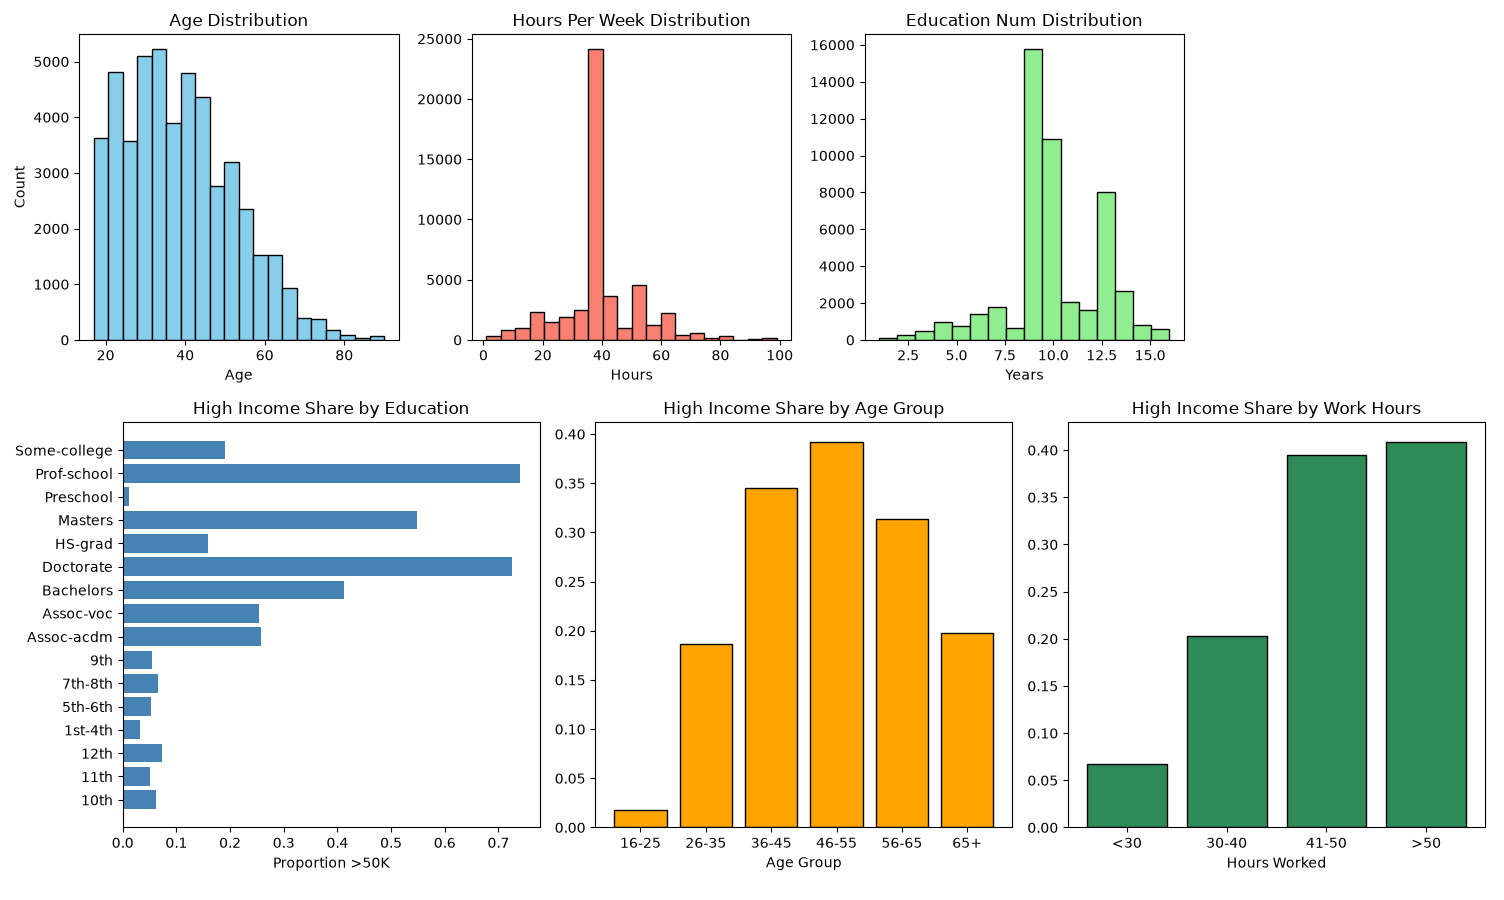